# 05 — η–R9 weight maps: 2023 postBPix vs 2024 with NF

Created 2026-10-05. Class: deliverable.

**Purpose.** Cell-by-cell comparison of the 2023 postBPix η–R9 weight map with the 2024 map with NF.

**Inputs** (`data/inputs/maps/`)
- `2023_R9_vs_eta_ratio_2023PostBPiX_vf.root` — copied from `/home/santanu/Pictures/Final_efficiency_for_low_mass_analysis_2023/eta_r9_reweighting/` (md5 checked below)
- `2024Lowmass_R9_vs_eta_ratio_presel.root` — the 2024 map with NF
- `data/cell_counts.npz` — only to check that the 2024 map read here is the one used in notebooks 01–04

**Outputs**: `plots/maps/map_2023_postBPix`, `map_2024_with_NF`, `map_2024_with_NF_over_2023`, `map_2024_with_NF_minus_2023`,
`map_slices_vs_r9_2023_vs_2024` (each `.pdf` + `.png`), `data/slide_numbers_05.json`

```mermaid
flowchart LR
 A[A Config] --> B[B Load both maps]
 B --> C[C Validate]
 C --> D[D Map, ratio and difference plots]
 C --> E[E Slices vs R9 per eta row]
 C --> F[F Numbers for slides]
```

Validation covers: md5 of the 2023 file; both maps have the same 25 × 16 binning; the 2024 map equals the one stored by notebook 01.
Not covered: how either map was produced, and whether the 2023 fits used exactly this 2023 file.

## [A] Config
`uproot` reads the ROOT histograms; `hashlib` computes the md5 checksum of a file; `matplotlib` draws.

In [1]:
# [A] Config
from pathlib import Path
import json, hashlib
import numpy as np
import uproot
import matplotlib.pyplot as plt
from matplotlib.colors import TwoSlopeNorm     # colour scale centred on a chosen value

STUDY = Path('/home/santanu/Desktop/HLT_2024_lowmass_final_with_NR_eta_r9_rw/etaR9_map_study')
MAPS  = STUDY / 'data' / 'inputs' / 'maps'
PLOTS = STUDY / 'plots' / 'maps'
F23   = MAPS / '2023_R9_vs_eta_ratio_2023PostBPiX_vf.root'
F24   = MAPS / '2024Lowmass_R9_vs_eta_ratio_presel.root'
MD5_23 = 'bc42e96dbb3d3e47cd74b17d351b9525'
L23, L24 = '2023 postBPix', '2024 with NF'
C23, C24 = '#2ca02c', '#d62728'                # same colours as the efficiency plots
plt.rcParams.update({'font.size': 11, 'axes.grid': True, 'grid.alpha': 0.35, 'grid.linestyle': ':'})

def save(fig, path):
    for ext in ('pdf', 'png'):
        fig.savefig(path.with_suffix('.' + ext), dpi=150, bbox_inches='tight')
    print(path.with_suffix('.pdf'))

## [B] Load both maps
`to_numpy` returns the cell contents and the bin edges of a 2D histogram (x = R9, y = |η|).

In [2]:
# [B] Load both maps
def load(p):
    with uproot.open(p) as f:
        return f['R9_vs_eta'].to_numpy()

M23, R9E, ETAE = load(F23)
M24, R9E24, ETAE24 = load(F24)
NX, NY = M23.shape
r9lab  = [f'{a:g}–{b:g}' for a, b in zip(R9E[:-1], R9E[1:])]
etalab = [f'{a:g}–{b:g}' for a, b in zip(ETAE[:-1], ETAE[1:])]
print('shape', M23.shape, '| 2023 range', M23.min(), M23.max(), '| 2024 range', M24.min(), M24.max())

shape (25, 16) | 2023 range 0.0 5.627914852749281 | 2024 range 0.0 5.932000644680022


## [C] Validate

In [3]:
# [C] Validate
assert hashlib.md5(F23.read_bytes()).hexdigest() == MD5_23
assert np.array_equal(R9E, R9E24) and np.array_equal(ETAE, ETAE24), 'the two maps do not share one binning'
Z = np.load(STUDY / 'data' / 'cell_counts.npz')
assert np.array_equal(M24, Z['map_new']) and np.array_equal(R9E, Z['r9_edges']) and np.array_equal(ETAE, Z['eta_edges'])
assert np.isfinite(M23).all() and np.isfinite(M24).all() and (M23 >= 0).all() and (M24 >= 0).all()
print('md5 ok | same binning | 2024 map identical to the one of notebook 01')

md5 ok | same binning | 2024 map identical to the one of notebook 01


## [D] Map, ratio and difference plots
Drawn in bin-index space as in notebook 02 (the R9 bins are not equally wide); tick labels give the edges; every cell is annotated.
Ratio = 2024 / 2023, left empty where the 2023 cell is 0.

/home/santanu/Desktop/HLT_2024_lowmass_final_with_NR_eta_r9_rw/etaR9_map_study/plots/maps/map_2023_postBPix.pdf


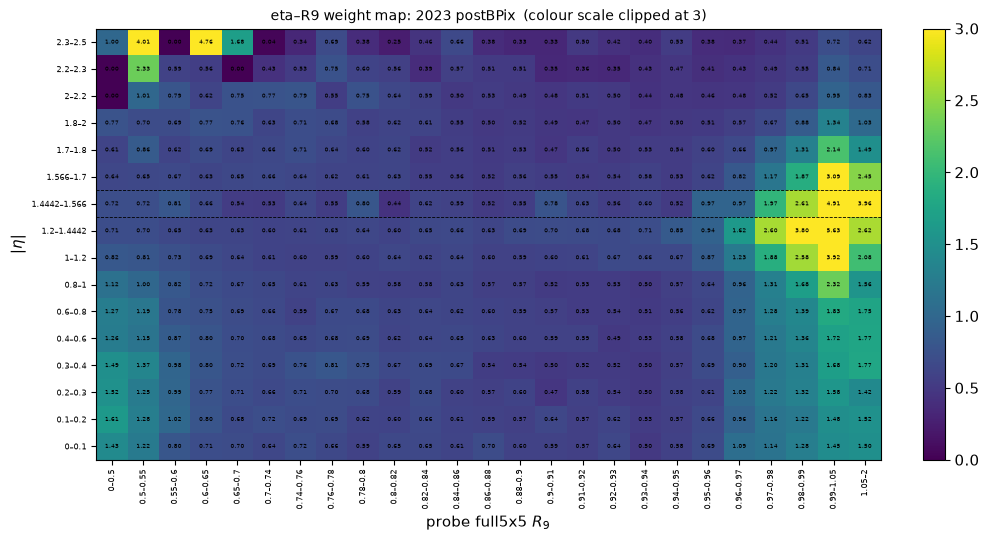

/home/santanu/Desktop/HLT_2024_lowmass_final_with_NR_eta_r9_rw/etaR9_map_study/plots/maps/map_2024_with_NF.pdf


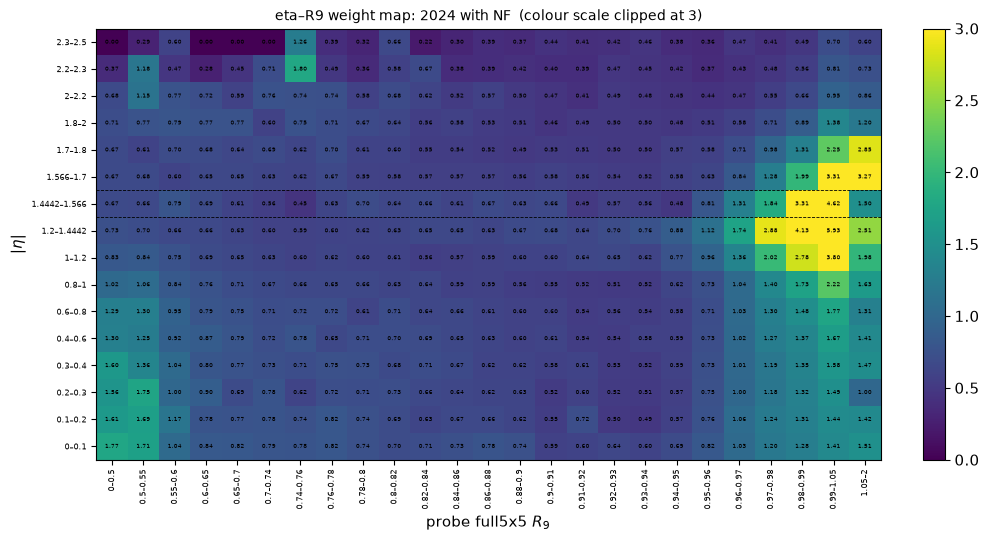

/home/santanu/Desktop/HLT_2024_lowmass_final_with_NR_eta_r9_rw/etaR9_map_study/plots/maps/map_2024_with_NF_over_2023.pdf


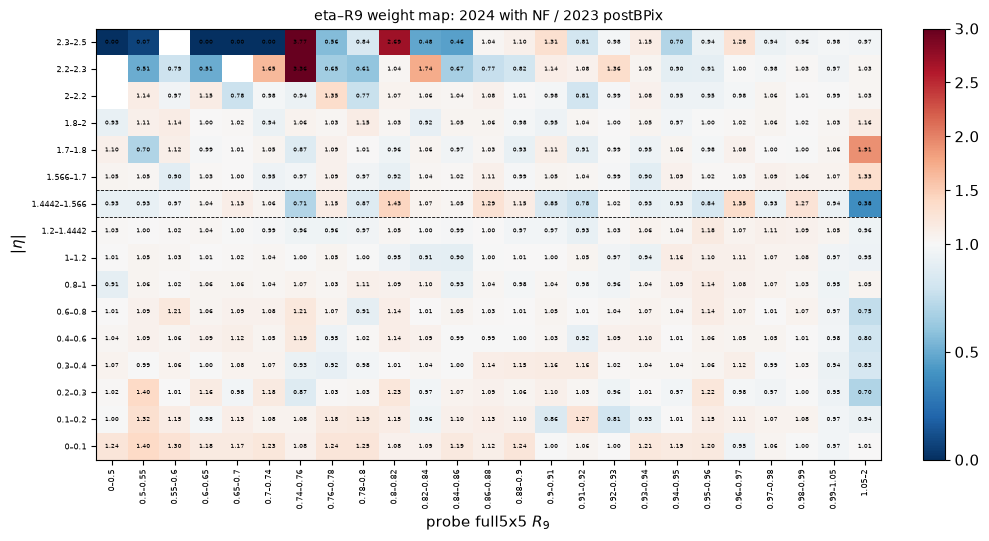

/home/santanu/Desktop/HLT_2024_lowmass_final_with_NR_eta_r9_rw/etaR9_map_study/plots/maps/map_2024_with_NF_minus_2023.pdf


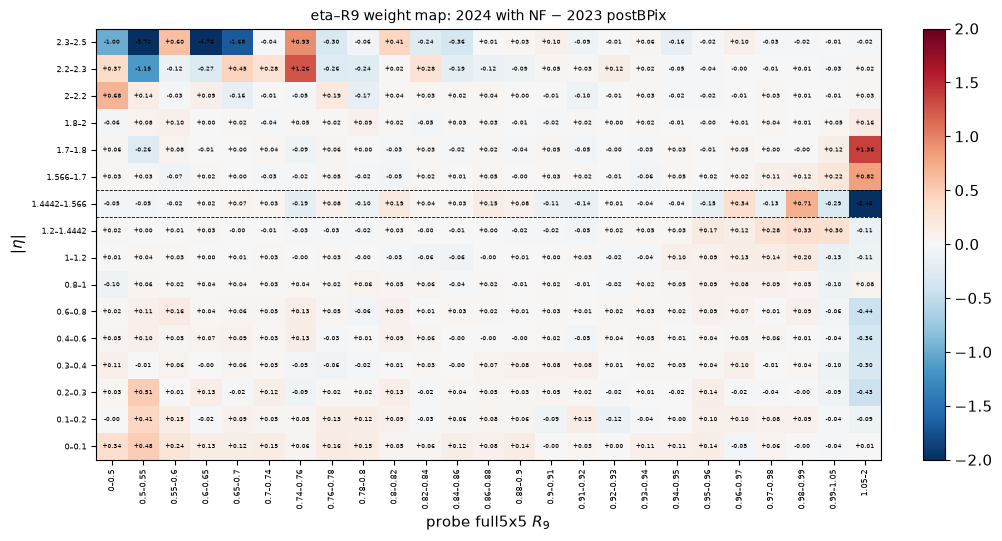

In [4]:
# [D] Map, ratio and difference plots
def grid_axes(a):
    a.set_xticks(range(NX)); a.set_xticklabels(r9lab, rotation=90, fontsize=6)
    a.set_yticks(range(NY)); a.set_yticklabels(etalab, fontsize=6)
    a.set_xlabel(r'probe full5x5 $R_9$'); a.set_ylabel(r'$|\eta|$'); a.grid(False)
    a.axhline(8.5, color='k', lw=0.6, ls='--'); a.axhline(9.5, color='k', lw=0.6, ls='--')   # EB/EE gap row (1.4442–1.566)

def annotate(a, M, fmt, size=4.6):
    for (i, j), v in np.ndenumerate(M):
        if np.isfinite(v):
            a.text(i, j, fmt.format(v), ha='center', va='center', fontsize=size)

with np.errstate(divide='ignore', invalid='ignore'):
    RATIO = np.where(M23 > 0, M24 / M23, np.nan)
DIFF = M24 - M23
panels = [(f'{L23}', 'map_2023_postBPix', M23, 'viridis', None, '{:.2f}'),
          (f'{L24}', 'map_2024_with_NF', M24, 'viridis', None, '{:.2f}'),
          (f'{L24} / {L23}', 'map_2024_with_NF_over_2023', RATIO, 'RdBu_r', TwoSlopeNorm(1, 0, 3), '{:.2f}'),
          (f'{L24} − {L23}', 'map_2024_with_NF_minus_2023', DIFF, 'RdBu_r', TwoSlopeNorm(0, -2, 2), '{:+.2f}')]
for name, fname, M, cmap, norm, fmt in panels:
    fig, a = plt.subplots(figsize=(11, 5.6))
    kw = dict(norm=norm) if norm else dict(vmin=0, vmax=3)
    im = a.imshow(M.T, origin='lower', cmap=cmap, aspect='auto', **kw)
    annotate(a, M, fmt); grid_axes(a); fig.colorbar(im, ax=a, fraction=0.03)
    a.set_title(f'eta–R9 weight map: {name}' + ('  (colour scale clipped at 3)' if norm is None else ''), fontsize=10)
    save(fig, PLOTS / fname)
    plt.show()

## [E] Slices vs R9 per η row
Map value vs R9 bin, one panel per |η| row, both maps overlaid. Shaded: the R9 windows of the analysis categories
(EB rows: 0.50–0.55, 0.55–0.85, > 0.85; EE rows: 0.90–0.93, > 0.93), as in notebook 02.

/home/santanu/Desktop/HLT_2024_lowmass_final_with_NR_eta_r9_rw/etaR9_map_study/plots/maps/map_slices_vs_r9_2023_vs_2024.pdf


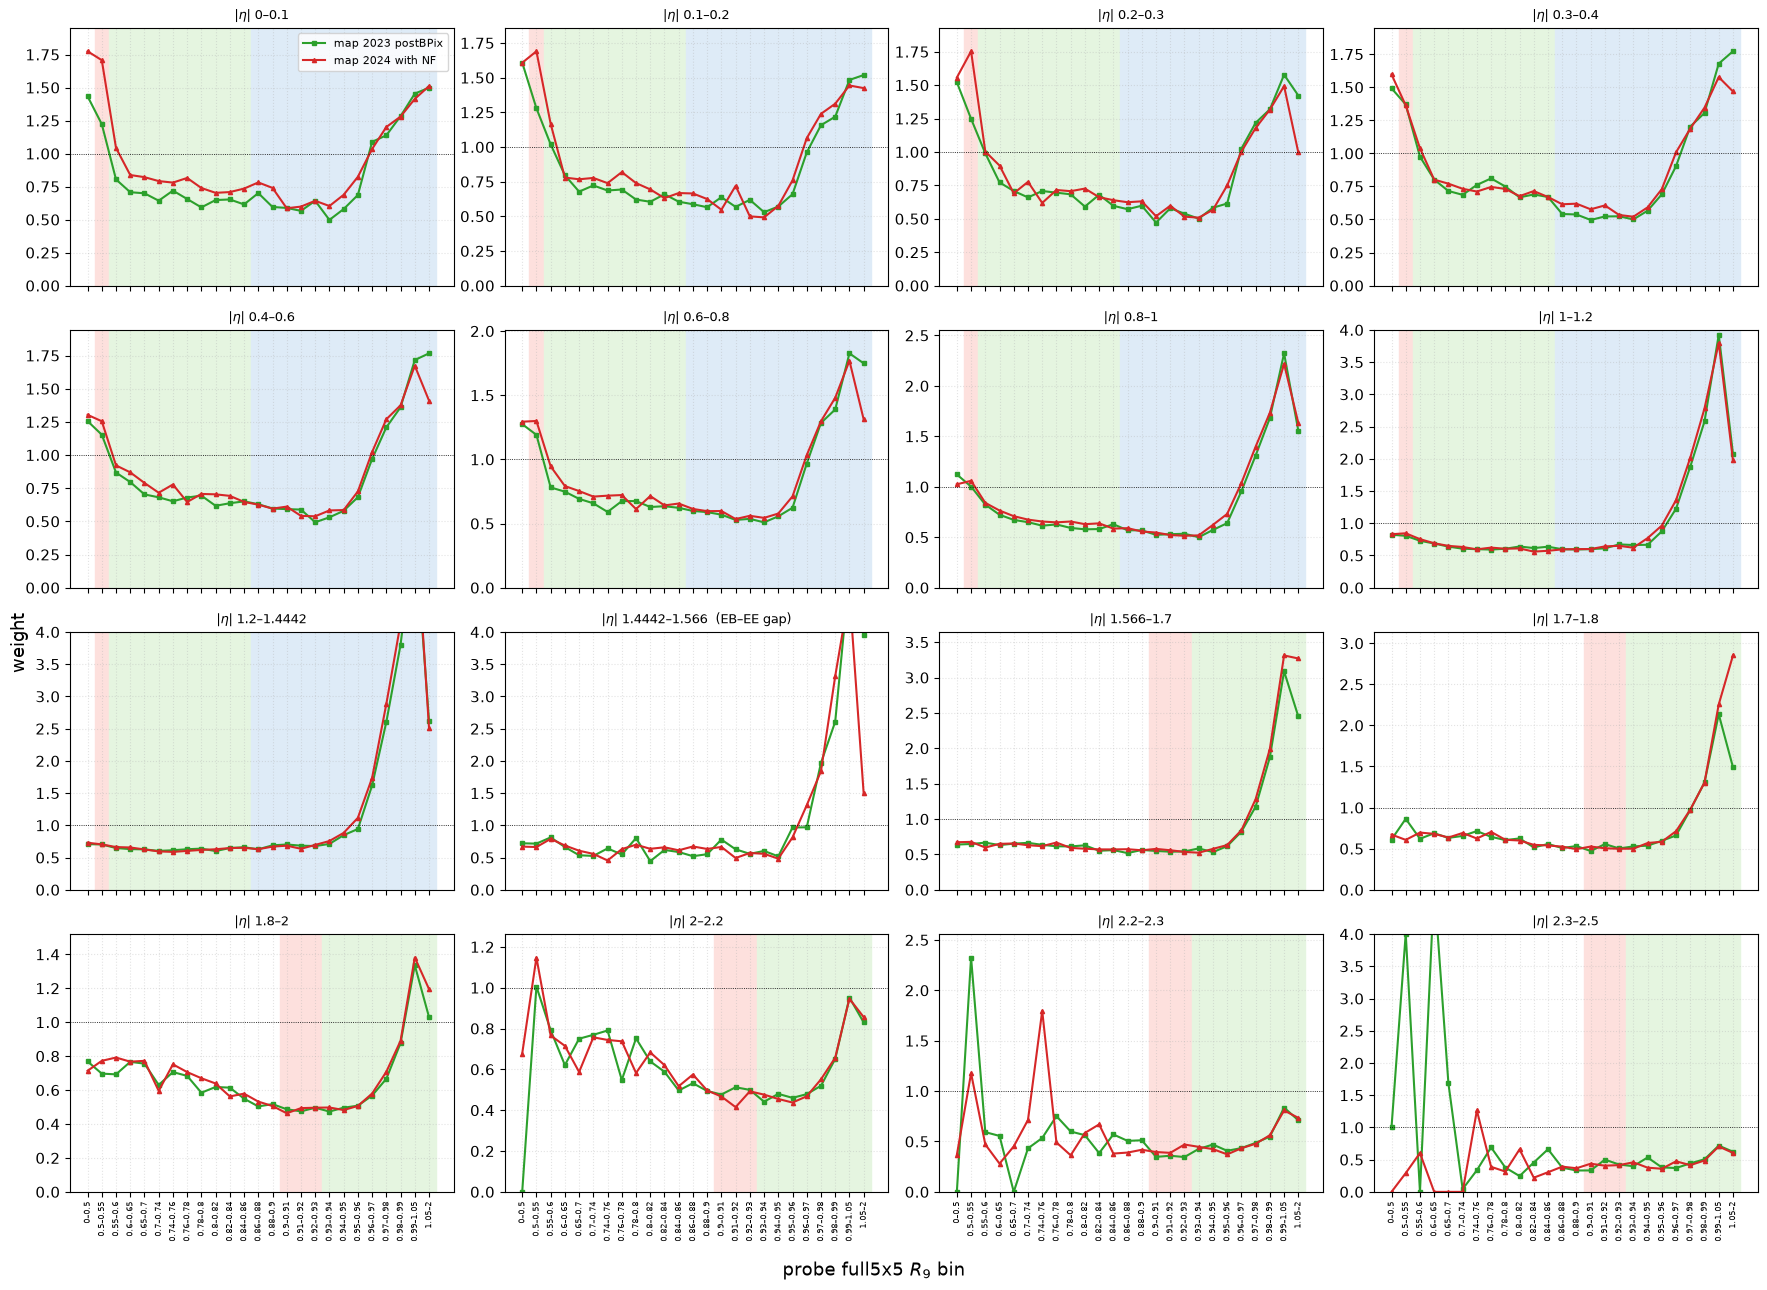

In [5]:
# [E] Slices vs R9 per eta row
CAT_R9 = {'EB': [(0.50, 0.55), (0.55, 0.85), (0.85, 2.0)], 'EE': [(0.90, 0.93), (0.93, 2.0)]}
def r9_idx(v):
    return int(np.searchsorted(R9E, v - 1e-9))
fig, axs = plt.subplots(4, 4, figsize=(18, 13), sharex=True)
for j, a in enumerate(axs.flat):
    reg = 'EB' if ETAE[j + 1] <= 1.4442 + 1e-6 else ('EE' if ETAE[j] >= 1.566 - 1e-6 else None)
    if reg:
        for k, (lo, hi) in enumerate(CAT_R9[reg]):
            a.axvspan(r9_idx(lo) - 0.5, r9_idx(hi) - 0.5, color=['#fde0dd', '#e5f5e0', '#deebf7'][k], zorder=0)
    a.plot(range(NX), M23[:, j], '-s', ms=3, color=C23, label=f'map {L23}')
    a.plot(range(NX), M24[:, j], '-^', ms=3, color=C24, label=f'map {L24}')
    a.axhline(1, color='k', lw=0.6, ls=':')
    a.set_title(rf'$|\eta|$ {etalab[j]}' + ('' if reg else '  (EB–EE gap)'), fontsize=9)
    a.set_ylim(0, min(4, max(M23[:, j].max(), M24[:, j].max()) * 1.1))
for a in axs[-1]:
    a.set_xticks(range(NX)); a.set_xticklabels(r9lab, rotation=90, fontsize=6)
axs[0, 0].legend(fontsize=8)
fig.supxlabel(r'probe full5x5 $R_9$ bin'); fig.supylabel('weight')
fig.tight_layout()
save(fig, PLOTS / 'map_slices_vs_r9_2023_vs_2024')
plt.show()

## [F] Numbers for slides
Cells in the analysis categories: EB rows with R9 > 0.50 and EE rows with R9 > 0.90 (the EB–EE gap row is excluded).

In [6]:
# [F] Numbers for slides
eb = ETAE[1:] <= 1.4442 + 1e-6; ee = ETAE[:-1] >= 1.566 - 1e-6
ANA = np.zeros((NX, NY), bool)
ANA[np.ix_(R9E[:-1] >= 0.50 - 1e-9, eb)] = True
ANA[np.ix_(R9E[:-1] >= 0.90 - 1e-9, ee)] = True
z23, z24 = M23 == 0, M24 == 0
num = dict(shape=[NX, NY],
           range_2023=[float(M23.min()), float(M23.max())], range_2024=[float(M24.min()), float(M24.max())],
           n_zero_2023=int(z23.sum()), n_zero_2024=int(z24.sum()), n_zero_both=int((z23 & z24).sum()),
           ratio_min=float(np.nanmin(RATIO)), ratio_max=float(np.nanmax(RATIO)),
           diff_min=float(DIFF.min()), diff_max=float(DIFF.max()), mean_abs_diff_all=float(np.abs(DIFF).mean()),
           n_cells_analysis=int(ANA.sum()), mean_abs_diff_analysis=float(np.abs(DIFF[ANA]).mean()),
           max_abs_diff_analysis=float(np.abs(DIFF[ANA]).max()),
           ratio_min_analysis=float(np.nanmin(RATIO[ANA])), ratio_max_analysis=float(np.nanmax(RATIO[ANA])),
           n_ratio_nan_analysis=int(np.isnan(RATIO[ANA]).sum()))
(STUDY / 'data' / 'slide_numbers_05.json').write_text(json.dumps(num, indent=1))
print(STUDY / 'data' / 'slide_numbers_05.json')
print(json.dumps(num, indent=1))

/home/santanu/Desktop/HLT_2024_lowmass_final_with_NR_eta_r9_rw/etaR9_map_study/data/slide_numbers_05.json
{
 "shape": [
  25,
  16
 ],
 "range_2023": [
  0.0,
  5.627914852749281
 ],
 "range_2024": [
  0.0,
  5.932000644680022
 ],
 "n_zero_2023": 4,
 "n_zero_2024": 4,
 "n_zero_both": 0,
 "ratio_min": 0.0,
 "ratio_max": 3.7652338954816735,
 "diff_min": -4.760065354244827,
 "diff_max": 1.3593947978477814,
 "mean_abs_diff_all": 0.12227218259261888,
 "n_cells_analysis": 282,
 "mean_abs_diff_analysis": 0.07108935515623836,
 "max_abs_diff_analysis": 1.3593947978477814,
 "ratio_min_analysis": 0.7006586723081744,
 "ratio_max_analysis": 1.9112609804747571,
 "n_ratio_nan_analysis": 0
}
